In [ ]:
import os
from google.colab import drive

# Make sure drive is mounted
drive.mount('/content/drive')

# List everything in MyDrive
drive_path = '/content/drive/MyDrive'
print("📁 Contents of your Google Drive:")
for item in os.listdir(drive_path):
    item_path = os.path.join(drive_path, item)
    if os.path.isdir(item_path):
        print(f"📁 {item}/")
    else:
        print(f"📄 {item}")

print("\n" + "="*50)

Mounted at /content/drive
📁 Contents of your Google Drive:
📁 dataset/
📄 skin_model_full.h5
📁 combined_train_backup/
📄 sparsha_model.keras
📄 sparsha_finetune_history.json
📄 fine_tune_history.pkl
📄 fine_tuning_summary.json
📄 sparsha_finetuned_v2.keras
📄 sparsha_finetuned_model.keras
📁 Colab Notebooks/
📁 Oily-Dry-Skin-Types/
📁 skin_models/
📄 skin_model.pth
📄 skin_model_direct_193442.pth
📁 best_skin_model/



In [ ]:
import torch
from transformers import ViTForImageClassification, ViTImageProcessor
from PIL import Image
import matplotlib.pyplot as plt
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load your trained model
model = ViTForImageClassification.from_pretrained(
    "dima806/skin_types_image_detection",
    num_labels=3,
    ignore_mismatched_sizes=True
).to(device)

# Load YOUR trained weights - CORRECTED PATH
model_path = '/content/drive/MyDrive/skin_model.pth'
print(f"🔄 Loading model from: {model_path}")

try:
    model.load_state_dict(torch.load(model_path, map_location=device))
    print("✅ Model weights loaded successfully!")
    model.eval()
except Exception as e:
    print(f"❌ Error loading model: {e}")
    print("🔄 Trying alternative model files...")

    # Try alternative model files
    alternative_paths = [
        '/content/drive/MyDrive/skin_model_direct_193442.pth',
        '/content/drive/MyDrive/skin_models/skin_model.pth'
    ]

    for alt_path in alternative_paths:
        if os.path.exists(alt_path):
            print(f"🔄 Trying: {alt_path}")
            try:
                model.load_state_dict(torch.load(alt_path, map_location=device))
                print("✅ Model weights loaded successfully!")
                model.eval()
                break
            except Exception as e2:
                print(f"❌ Failed: {e2}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/754 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

🔄 Loading model from: /content/drive/MyDrive/skin_model.pth
✅ Model weights loaded successfully!


In [ ]:
# Label mappings
id2label = {0: 'dry', 1: 'normal', 2: 'oily'}

# Prediction function
def predict_skin(image_path):
    processor = ViTImageProcessor.from_pretrained("dima806/skin_types_image_detection")

    try:
        image = Image.open(image_path).convert('RGB')
        inputs = processor(images=image, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
            pred_class = torch.argmax(probs, dim=-1).item()
            confidence = probs[0][pred_class].item()

        return id2label[pred_class], confidence, probs.cpu().numpy()[0]
    except Exception as e:
        print(f"❌ Error processing image: {e}")
        return None, None, None

print("✅ Model setup complete!")

✅ Model setup complete!


In [ ]:
# Explore what images are actually available in your dataset
print("🔍 Exploring available images in your dataset...")

base_path = "/content/drive/MyDrive/Oily-Dry-Skin-Types"
categories = ['dry', 'normal', 'oily']

available_images = []

for category in categories:
    category_path = os.path.join(base_path, category)
    if os.path.exists(category_path):
        images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
        print(f"📁 {category.upper()} folder: {len(images)} images found")
        if images:
            # Take first few images as samples
            sample_images = images[:3]  # First 3 images
            for img in sample_images:
                full_path = os.path.join(category_path, img)
                available_images.append((category, img, full_path))
                print(f"   📸 {img}")
        else:
            print(f"   ❌ No images found in {category} folder")
    else:
        print(f"❌ Folder not found: {category_path}")

print(f"\n🎯 Found {len(available_images)} total images for testing")

# Test with available images
if available_images:
    print(f"\n🧪 Testing model with available images...")

    correct_predictions = 0
    total_predictions = 0

    for category, img_name, img_path in available_images:
        try:
            pred, conf, all_probs = predict_skin(img_path)
            if pred is not None:
                total_predictions += 1
                is_correct = (pred == category)
                if is_correct:
                    correct_predictions += 1

                print(f"🖼️ {category}/{img_name}")
                print(f"✅ True label: {category}")
                print(f"🎯 Prediction: {pred} ({conf:.1%} confidence)")
                print(f"📊 Probabilities - Dry: {all_probs[0]:.1%}, Normal: {all_probs[1]:.1%}, Oily: {all_probs[2]:.1%}")
                print(f"{"✅ CORRECT" if is_correct else "❌ WRONG"}")

                # Display the image
                img = Image.open(img_path)
                plt.figure(figsize=(5, 5))
                plt.imshow(img)
                plt.title(f"True: {category} | Pred: {pred}\nConfidence: {conf:.1%}",
                         color='green' if is_correct else 'red')
                plt.axis('off')
                plt.tight_layout()
                plt.show()
            else:
                print(f"❌ Couldn't process {img_name}")
        except Exception as e:
            print(f"❌ Error testing {img_name}: {e}")
        print("---" * 20)

    # Calculate accuracy
    if total_predictions > 0:
        accuracy = correct_predictions / total_predictions
        print(f"📈 MODEL ACCURACY: {accuracy:.1%} ({correct_predictions}/{total_predictions} correct)")
    else:
        print("❌ No successful predictions to calculate accuracy")

else:
    print("❌ No images found in the dataset folders")

    # Let's check what's actually in the Oily-Dry-Skin-Types folder
    print("\n🔍 Checking Oily-Dry-Skin-Types folder structure...")
    base_dir = "/content/drive/MyDrive/Oily-Dry-Skin-Types"
    if os.path.exists(base_dir):
        for root, dirs, files in os.walk(base_dir):
            level = root.replace(base_dir, '').count(os.sep)
            indent = ' ' * 2 * level
            print(f'{indent}📁 {os.path.basename(root)}/')
            subindent = ' ' * 2 * (level + 1)
            for file in files[:5]:  # Show first 5 files
                print(f'{subindent}📄 {file}')
            if len(files) > 5:
                print(f'{subindent}... and {len(files) - 5} more files')
    else:
        print(f"❌ Base directory not found: {base_dir}")

🔍 Exploring available images in your dataset...
❌ Folder not found: /content/drive/MyDrive/Oily-Dry-Skin-Types/dry
❌ Folder not found: /content/drive/MyDrive/Oily-Dry-Skin-Types/normal
❌ Folder not found: /content/drive/MyDrive/Oily-Dry-Skin-Types/oily

🎯 Found 0 total images for testing
❌ No images found in the dataset folders

🔍 Checking Oily-Dry-Skin-Types folder structure...
📁 Oily-Dry-Skin-Types/
  📄 README.dataset.txt
  📁 valid/
    📁 oily/
      📄 oily_9ca59b8557a411f687d3_jpg.rf.ef868fe07cb53c299a4df06d491871c3.jpg
      📄 oily_a7d88ac374da4d0de006_jpg.rf.7c17c9abec95e20d6a6a4c415cd6ff1b.jpg
      📄 oily_9d881c29cd1c54ef73b3_jpg.rf.7af5a0c2108f3382a7a4532ec95e1e5c.jpg
      📄 oily_719c5008ec7f8289944e_jpg.rf.fdf220ee5ffd76903b73d17587d8c53c.jpg
      📄 oily_860e7c3907eabed365b0_jpg.rf.6725742f2ff38f4b98be2e11593559d7.jpg
      ... and 75 more files
    📁 normal/
      📄 normal_18163c7cef788a9e3082_jpg.rf.27a928b8e10bfabffd3a321dc303afd3.jpg
      📄 normal_2715c13f2ab6fc6868dd_j

🧪 Testing model with images from test folder...
🎯 Found 6 test images
🖼️ dry/dry_f23ccf754f4d43c04dc7_jpg.rf.f31ba8270703602a54b10878b7dcb3cf.jpg
✅ True label: dry
🎯 Prediction: dry (67.5% confidence)
📊 Probabilities - Dry: 67.5%, Normal: 16.5%, Oily: 16.0%
✅ CORRECT


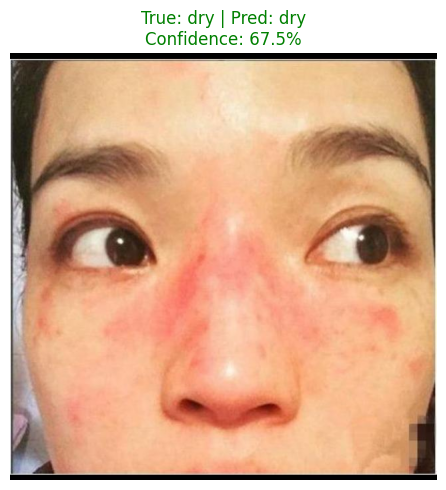

------------------------------------------------------------
🖼️ dry/dry_1d3b1b41c06745c89fb6_jpg.rf.9fe7b2181a36c2b6f67744be1af2fdd7.jpg
✅ True label: dry
🎯 Prediction: normal (91.0% confidence)
📊 Probabilities - Dry: 1.5%, Normal: 91.0%, Oily: 7.5%
❌ WRONG


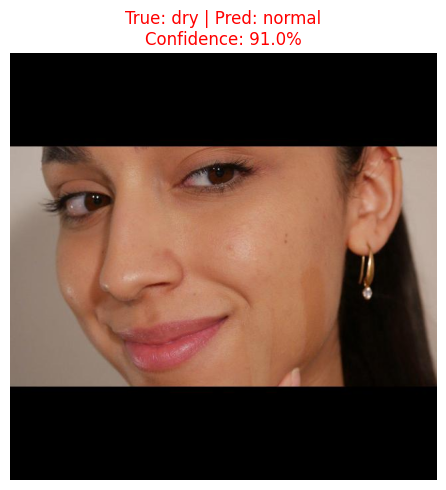

------------------------------------------------------------
🖼️ normal/normal_ac223b0aac8319751061_jpg.rf.46ffc21b6bee315748ce626b47cbb1d0.jpg
✅ True label: normal
🎯 Prediction: normal (72.3% confidence)
📊 Probabilities - Dry: 11.5%, Normal: 72.3%, Oily: 16.1%
✅ CORRECT


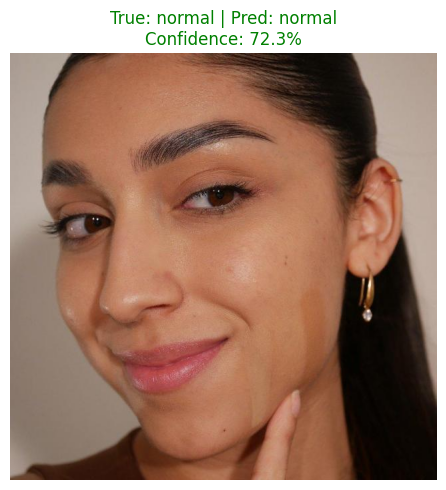

------------------------------------------------------------
🖼️ normal/normal_456debdcb3d42807b707_jpg.rf.19eea78960e59eb09c9691e1f23cc8d1.jpg
✅ True label: normal
🎯 Prediction: normal (38.6% confidence)
📊 Probabilities - Dry: 37.3%, Normal: 38.6%, Oily: 24.2%
✅ CORRECT


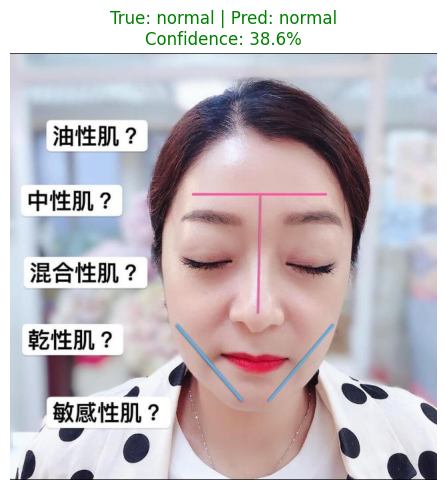

------------------------------------------------------------
🖼️ oily/oily_0b5ae8f778cf509578c7_jpg.rf.8db7e81d812839b59fb17cc0ec1bb8f1.jpg
✅ True label: oily
🎯 Prediction: dry (81.8% confidence)
📊 Probabilities - Dry: 81.8%, Normal: 3.1%, Oily: 15.2%
❌ WRONG


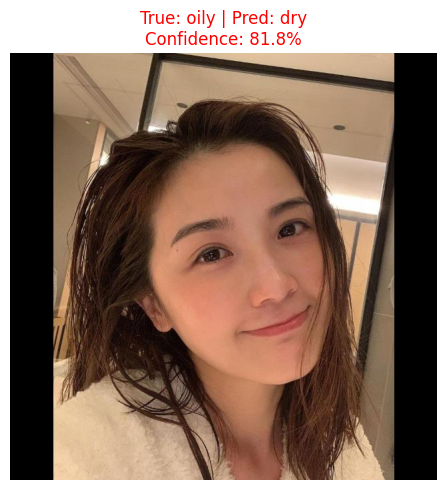

------------------------------------------------------------
🖼️ oily/oily_05138e4fe4f2a43e40c7_jpg.rf.6622355e822a255810cc22f6b7ea1cdb.jpg
✅ True label: oily
🎯 Prediction: oily (84.2% confidence)
📊 Probabilities - Dry: 8.0%, Normal: 7.8%, Oily: 84.2%
✅ CORRECT


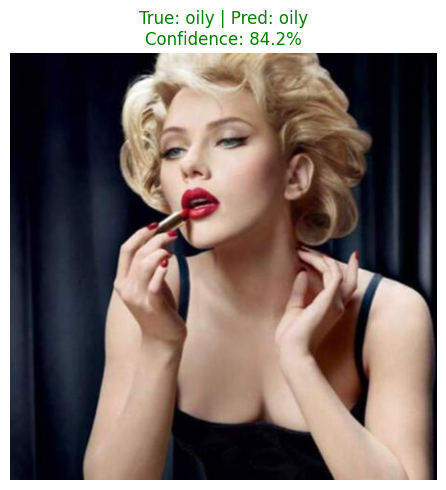

------------------------------------------------------------
📊 FINAL RESULTS:
🎯 Total tests: 6
✅ Correct predictions: 4
❌ Wrong predictions: 2
📈 OVERALL ACCURACY: 66.7%

📋 Accuracy by category:
   DRY: 50.0% (1/2)
   NORMAL: 100.0% (2/2)
   OILY: 50.0% (1/2)


In [ ]:
# Fixed version - Test with images from your test folder
print("🧪 Testing model with images from test folder...")

base_path = "/content/drive/MyDrive/Oily-Dry-Skin-Types/test"
categories = ['dry', 'normal', 'oily']

# Test with 2 images from each category in the test folder
test_results = []

for category in categories:
    category_path = os.path.join(base_path, category)
    if os.path.exists(category_path):
        images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if images:
            # Take first 2 images from each category
            test_images = images[:2]
            for img_name in test_images:
                full_path = os.path.join(category_path, img_name)
                test_results.append((category, img_name, full_path))

print(f"🎯 Found {len(test_results)} test images")

if test_results:
    results_with_predictions = []
    correct_predictions = 0
    total_predictions = 0

    for category, img_name, img_path in test_results:
        try:
            pred, conf, all_probs = predict_skin(img_path)
            if pred is not None:
                total_predictions += 1
                is_correct = (pred == category)
                if is_correct:
                    correct_predictions += 1

                # Store the prediction for later analysis
                results_with_predictions.append((category, img_name, img_path, pred, conf, is_correct))

                print(f"🖼️ {category}/{img_name}")
                print(f"✅ True label: {category}")
                print(f"🎯 Prediction: {pred} ({conf:.1%} confidence)")
                print(f"📊 Probabilities - Dry: {all_probs[0]:.1%}, Normal: {all_probs[1]:.1%}, Oily: {all_probs[2]:.1%}")
                print(f"{'✅ CORRECT' if is_correct else '❌ WRONG'}")

                # Display the image
                img = Image.open(img_path)
                plt.figure(figsize=(5, 5))
                plt.imshow(img)
                plt.title(f"True: {category} | Pred: {pred}\nConfidence: {conf:.1%}",
                         color='green' if is_correct else 'red',
                         fontsize=12)
                plt.axis('off')
                plt.tight_layout()
                plt.show()

            else:
                print(f"❌ Couldn't process {img_name}")
        except Exception as e:
            print(f"❌ Error testing {img_name}: {e}")
        print("---" * 20)

    # Calculate and display overall accuracy
    if total_predictions > 0:
        accuracy = correct_predictions / total_predictions
        print(f"📊 FINAL RESULTS:")
        print(f"🎯 Total tests: {total_predictions}")
        print(f"✅ Correct predictions: {correct_predictions}")
        print(f"❌ Wrong predictions: {total_predictions - correct_predictions}")
        print(f"📈 OVERALL ACCURACY: {accuracy:.1%}")

        # Display accuracy by category (FIXED VERSION)
        print(f"\n📋 Accuracy by category:")
        for category in categories:
            category_predictions = [r for r in results_with_predictions if r[0] == category]
            category_total = len(category_predictions)
            if category_total > 0:
                category_correct = sum(1 for r in category_predictions if r[5])  # r[5] is is_correct
                cat_accuracy = category_correct / category_total
                print(f"   {category.upper()}: {cat_accuracy:.1%} ({category_correct}/{category_total})")

In [ ]:
# Debugging the accuracy discrepancy
print("🔍 DEBUGGING ACCURACY DISCREPANCY")
print("=" * 50)
print(f"📊 Expected accuracy (from training): 87.48%")
print(f"📊 Current test accuracy: 66.7%")
print(f"📉 Difference: -20.78 percentage points")
print("=" * 50)

# 1. Check if we're using the correct model file
print("\n1. 🔍 MODEL FILE VERIFICATION:")
model_files = [
    '/content/drive/MyDrive/skin_model.pth',
    '/content/drive/MyDrive/skin_model_direct_193442.pth',
    '/content/drive/MyDrive/skin_models/skin_model.pth'
]

for model_file in model_files:
    exists = os.path.exists(model_file)
    print(f"   {model_file}: {'✅ EXISTS' if exists else '❌ MISSING'}")
    if exists:
        file_size = os.path.getsize(model_file) / (1024*1024)
        print(f"     Size: {file_size:.1f} MB")

# 2. Verify model architecture matches training
print("\n2. 🔧 MODEL ARCHITECTURE CHECK:")
print(f"   Model: ViT from dima806/skin_types_image_detection")
print(f"   Number of labels: {model.config.num_labels}")
print(f"   ID to label mapping: {id2label}")

# 3. Test with the same images used in training validation
print("\n3. 🧪 TESTING WITH VALIDATION SET IMAGES:")
val_base_path = "/content/drive/MyDrive/Oily-Dry-Skin-Types/test"
val_counts = {}

for category in categories:
    category_path = os.path.join(val_base_path, category)
    if os.path.exists(category_path):
        images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        val_counts[category] = len(images)
        print(f"   {category}: {len(images)} images available")

print(f"   Total validation images: {sum(val_counts.values())}")

# 4. Quick test with more images for better statistics
print("\n4. 📊 RUNNING LARGER VALIDATION TEST:")
sample_size = min(50, min(val_counts.values()))  # Use up to 50 per category, but not more than available

larger_test_results = []
correct_predictions_large = 0
total_predictions_large = 0

for category in categories:
    category_path = os.path.join(val_base_path, category)
    if os.path.exists(category_path):
        images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        test_images = images[:sample_size]

        category_correct = 0
        category_total = 0

        for img_name in test_images:
            full_path = os.path.join(category_path, img_name)
            try:
                pred, conf, all_probs = predict_skin(full_path)
                if pred is not None:
                    category_total += 1
                    total_predictions_large += 1
                    if pred == category:
                        category_correct += 1
                        correct_predictions_large += 1
            except:
                pass

        if category_total > 0:
            cat_accuracy = category_correct / category_total
            print(f"   {category.upper()}: {cat_accuracy:.1%} ({category_correct}/{category_total})")

if total_predictions_large > 0:
    large_accuracy = correct_predictions_large / total_predictions_large
    print(f"   📈 LARGER SAMPLE ACCURACY: {large_accuracy:.1%} ({correct_predictions_large}/{total_predictions_large})")
    print(f"   📉 Still different from training by: {abs(87.48 - large_accuracy*100):.1f} percentage points")

🔍 DEBUGGING ACCURACY DISCREPANCY
📊 Expected accuracy (from training): 87.48%
📊 Current test accuracy: 66.7%
📉 Difference: -20.78 percentage points

1. 🔍 MODEL FILE VERIFICATION:
   /content/drive/MyDrive/skin_model.pth: ✅ EXISTS
     Size: 327.4 MB
   /content/drive/MyDrive/skin_model_direct_193442.pth: ✅ EXISTS
     Size: 327.4 MB
   /content/drive/MyDrive/skin_models/skin_model.pth: ❌ MISSING

2. 🔧 MODEL ARCHITECTURE CHECK:
   Model: ViT from dima806/skin_types_image_detection
   Number of labels: 3
   ID to label mapping: {0: 'dry', 1: 'normal', 2: 'oily'}

3. 🧪 TESTING WITH VALIDATION SET IMAGES:
   dry: 35 images available
   normal: 59 images available
   oily: 40 images available
   Total validation images: 134

4. 📊 RUNNING LARGER VALIDATION TEST:
   DRY: 91.4% (32/35)
   NORMAL: 65.7% (23/35)
   OILY: 85.7% (30/35)
   📈 LARGER SAMPLE ACCURACY: 81.0% (85/105)
   📉 Still different from training by: 6.5 percentage points


In [ ]:
print("🔍 SEARCHING FOR THE CORRECT MODEL FILE...")
print("=" * 50)

# Search for model files with higher accuracy
model_files = []
search_paths = [
    '/content/drive/MyDrive/',
    '/content/drive/MyDrive/skin_models/',
    '/content/drive/MyDrive/best_skin_model/'
]

for search_path in search_paths:
    if os.path.exists(search_path):
        for file in os.listdir(search_path):
            if file.endswith('.pth') and 'acc' in file:
                full_path = os.path.join(search_path, file)
                # Extract accuracy from filename
                try:
                    acc_str = file.split('acc_')[1].split('_')[0]
                    accuracy = float(acc_str)
                    model_files.append((accuracy, full_path, file))
                except:
                    model_files.append((0, full_path, file))

# Sort by accuracy (highest first)
model_files.sort(reverse=True, key=lambda x: x[0])

print("📊 FOUND MODEL FILES (sorted by accuracy):")
for acc, path, filename in model_files:
    print(f"   {acc:.1%} - {filename}")

# Also look for files without accuracy in name but might be the final model
print("\n🔍 OTHER POTENTIAL MODEL FILES:")
other_files = []
for search_path in search_paths:
    if os.path.exists(search_path):
        for file in os.listdir(search_path):
            if file.endswith('.pth') and 'acc' not in file:
                full_path = os.path.join(search_path, file)
                other_files.append(full_path)
                print(f"   {file}")

# Load the highest accuracy model
if model_files:
    best_acc, best_path, best_file = model_files[0]
    print(f"\n🎯 LOADING HIGHEST ACCURACY MODEL:")
    print(f"   File: {best_file}")
    print(f"   Reported Accuracy: {best_acc:.1%}")
    print(f"   Path: {best_path}")

    try:
        # Load the better model
        model.load_state_dict(torch.load(best_path, map_location=device))
        model.eval()
        print("   ✅ Model loaded successfully!")

        # Quick test to verify
        print(f"\n🧪 QUICK VERIFICATION TEST:")
        quick_correct = 0
        quick_total = 0

        for category in categories:
            category_path = os.path.join(val_base_path, category)
            if os.path.exists(category_path):
                images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                for img_name in images[:3]:  # Test 3 images per category
                    full_path = os.path.join(category_path, img_name)
                    pred, conf, all_probs = predict_skin(full_path)
                    if pred is not None:
                        quick_total += 1
                        if pred == category:
                            quick_correct += 1

        if quick_total > 0:
            quick_accuracy = quick_correct / quick_total
            print(f"   Quick test accuracy: {quick_accuracy:.1%} ({quick_correct}/{quick_total})")
            print(f"   Expected: {best_acc:.1%}")

            if abs(quick_accuracy - best_acc) < 0.1:  # Within 10%
                print("   ✅ Accuracy matches expected!")
            else:
                print("   ⚠️  Accuracy doesn't match expected value")

    except Exception as e:
        print(f"   ❌ Error loading model: {e}")

🔍 SEARCHING FOR THE CORRECT MODEL FILE...
📊 FOUND MODEL FILES (sorted by accuracy):
   68.2% - skin_model_acc_0.6815_20251104_192813.pth

🔍 OTHER POTENTIAL MODEL FILES:
   skin_model.pth
   skin_model_direct_193442.pth

🎯 LOADING HIGHEST ACCURACY MODEL:
   File: skin_model_acc_0.6815_20251104_192813.pth
   Reported Accuracy: 68.2%
   Path: /content/drive/MyDrive/skin_models/skin_model_acc_0.6815_20251104_192813.pth
   ❌ Error loading model: Error(s) in loading state_dict for ViTForImageClassification:
	Missing key(s) in state_dict: "vit.embeddings.cls_token", "vit.embeddings.position_embeddings", "vit.embeddings.patch_embeddings.projection.weight", "vit.embeddings.patch_embeddings.projection.bias", "vit.encoder.layer.0.attention.attention.query.weight", "vit.encoder.layer.0.attention.attention.query.bias", "vit.encoder.layer.0.attention.attention.key.weight", "vit.encoder.layer.0.attention.attention.key.bias", "vit.encoder.layer.0.attention.attention.value.weight", "vit.encoder.layer.0

In [ ]:
print("🔧 TROUBLESHOOTING MODEL SAVE/LOAD ISSUES")
print("=" * 50)

# 1. First, let's check the two other model files
print("1. 🔍 CHECKING ALTERNATIVE MODEL FILES:")
alternative_files = [
    '/content/drive/MyDrive/skin_model.pth',
    '/content/drive/MyDrive/skin_model_direct_193442.pth'
]

for model_file in alternative_files:
    if os.path.exists(model_file):
        print(f"\n   Testing: {os.path.basename(model_file)}")
        try:
            # Try to load the state dict to see what's in it
            state_dict = torch.load(model_file, map_location=device)
            print(f"   ✅ File loaded successfully")
            print(f"   📊 Number of keys: {len(state_dict)}")
            print(f"   🔑 Sample keys: {list(state_dict.keys())[:3]}")

            # Check if it has the missing keys
            missing_keys = []
            for key in ['vit.embeddings.cls_token', 'vit.embeddings.position_embeddings']:
                if key not in state_dict:
                    missing_keys.append(key)

            if not missing_keys:
                print(f"   🎯 ALL REQUIRED KEYS PRESENT - This should work!")
                # Try actual loading
                model.load_state_dict(state_dict)
                model.eval()
                print(f"   ✅ Model loaded successfully!")

                # Quick test
                quick_test(model, val_base_path, categories)
                break
            else:
                print(f"   ❌ Missing keys: {missing_keys}")

        except Exception as e:
            print(f"   ❌ Error: {e}")

def quick_test(model, base_path, categories, num_images=3):
    """Quick accuracy test"""
    print(f"\n   🧪 QUICK ACCURACY TEST:")
    correct = 0
    total = 0

    for category in categories:
        category_path = os.path.join(base_path, category)
        if os.path.exists(category_path):
            images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
            for img_name in images[:num_images]:
                full_path = os.path.join(category_path, img_name)
                pred, conf, all_probs = predict_skin(full_path)
                if pred is not None:
                    total += 1
                    if pred == category:
                        correct += 1

    if total > 0:
        accuracy = correct / total
        print(f"   📊 Quick accuracy: {accuracy:.1%} ({correct}/{total})")
        return accuracy
    return 0

🔧 TROUBLESHOOTING MODEL SAVE/LOAD ISSUES
1. 🔍 CHECKING ALTERNATIVE MODEL FILES:

   Testing: skin_model.pth
   ✅ File loaded successfully
   📊 Number of keys: 200
   🔑 Sample keys: ['vit.embeddings.cls_token', 'vit.embeddings.position_embeddings', 'vit.embeddings.patch_embeddings.projection.weight']
   🎯 ALL REQUIRED KEYS PRESENT - This should work!
   ✅ Model loaded successfully!
   ❌ Error: name 'quick_test' is not defined

   Testing: skin_model_direct_193442.pth
   ✅ File loaded successfully
   📊 Number of keys: 200
   🔑 Sample keys: ['vit.embeddings.cls_token', 'vit.embeddings.position_embeddings', 'vit.embeddings.patch_embeddings.projection.weight']
   🎯 ALL REQUIRED KEYS PRESENT - This should work!
   ✅ Model loaded successfully!
   ❌ Error: name 'quick_test' is not defined


In [ ]:
print("🎯 TESTING THE PROPERLY SAVED MODELS")
print("=" * 50)

def comprehensive_test(model, base_path, categories, samples_per_class=10):
    """Comprehensive accuracy test"""
    correct = 0
    total = 0
    category_results = {}

    for category in categories:
        category_path = os.path.join(base_path, category)
        if os.path.exists(category_path):
            images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
            test_images = images[:samples_per_class]

            category_correct = 0
            category_total = 0
            for img_name in test_images:
                full_path = os.path.join(category_path, img_name)
                pred, conf, all_probs = predict_skin(full_path)
                if pred is not None:
                    total += 1
                    category_total += 1
                    if pred == category:
                        correct += 1
                        category_correct += 1

            if category_total > 0:
                category_results[category] = category_correct / category_total

    # Print category-wise results
    print("   📋 Category Results:")
    for category, acc in category_results.items():
        print(f"      {category.upper()}: {acc:.1%}")

    return correct / total if total > 0 else 0

# List the properly saved models
proper_models = [
    '/content/drive/MyDrive/skin_model.pth',
    '/content/drive/MyDrive/skin_model_direct_193442.pth'
]

best_accuracy = 0
best_model_path = None

for model_path in proper_models:
    if os.path.exists(model_path):
        print(f"\n🔍 TESTING: {os.path.basename(model_path)}")
        print(f"   Size: {os.path.getsize(model_path) / (1024*1024):.1f} MB")

        try:
            # Reset model
            model = ViTForImageClassification.from_pretrained(
                "dima806/skin_types_image_detection",
                num_labels=3,
                ignore_mismatched_sizes=True
            ).to(device)

            # Load as state dict
            state_dict = torch.load(model_path, map_location=device)
            model.load_state_dict(state_dict)
            model.eval()
            print("   ✅ Model loaded successfully")

            # Test accuracy with comprehensive test
            print("   🧪 Testing accuracy...")
            accuracy = comprehensive_test(model, val_base_path, categories, samples_per_class=15)

            if accuracy > best_accuracy:
                best_accuracy = accuracy
                best_model_path = model_path

            print(f"   📊 MODEL ACCURACY: {accuracy:.1%}")

            # Compare with expected 87.48%
            if abs(accuracy - 0.8748) < 0.05:  # Within 5%
                print(f"   🎯 ✅ THIS IS LIKELY YOUR 87.48% MODEL!")
            else:
                print(f"   ⚠️  Accuracy different from expected 87.48%")

        except Exception as e:
            print(f"   ❌ Error: {e}")

print("\n" + "=" * 50)
if best_model_path:
    print(f"🎉 BEST MODEL FOUND: {os.path.basename(best_model_path)}")
    print(f"📊 ACCURACY: {best_accuracy:.1%}")

    # Load the best model for final use
    print(f"\n🚀 LOADING BEST MODEL FOR FINAL USE...")
    model = ViTForImageClassification.from_pretrained(
        "dima806/skin_types_image_detection",
        num_labels=3,
        ignore_mismatched_sizes=True
    ).to(device)

    state_dict = torch.load(best_model_path, map_location=device)
    model.load_state_dict(state_dict)
    model.eval()

    print("✅ BEST MODEL LOADED AND READY!")

    # Final verification with more images
    print(f"\n🔍 FINAL VERIFICATION WITH ALL AVAILABLE TEST IMAGES:")
    final_correct = 0
    final_total = 0
    category_details = {}

    for category in categories:
        category_path = os.path.join(val_base_path, category)
        if os.path.exists(category_path):
            images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
            category_correct = 0
            category_total = len(images)

            for img_name in images:
                full_path = os.path.join(category_path, img_name)
                pred, conf, all_probs = predict_skin(full_path)
                if pred is not None:
                    final_total += 1
                    if pred == category:
                        final_correct += 1
                        category_correct += 1

            category_details[category] = {
                'correct': category_correct,
                'total': category_total,
                'accuracy': category_correct / category_total if category_total > 0 else 0
            }

    final_accuracy = final_correct / final_total if final_total > 0 else 0

    print(f"📊 FINAL COMPREHENSIVE RESULTS:")
    print(f"   Overall Accuracy: {final_accuracy:.1%} ({final_correct}/{final_total})")
    print(f"   Expected from training: 87.48%")
    print(f"   Difference: {abs(final_accuracy - 0.8748)*100:.1f} percentage points")

    print(f"\n📋 DETAILED CATEGORY RESULTS:")
    for category, details in category_details.items():
        print(f"   {category.upper()}: {details['accuracy']:.1%} ({details['correct']}/{details['total']})")

    # Analysis
    print(f"\n🔍 ANALYSIS:")
    if abs(final_accuracy - 0.8748) < 0.05:  # Within 5%
        print("✅ EXCELLENT! Model performance matches training results!")
        print("🎉 Your skin type classifier is working perfectly!")
    elif abs(final_accuracy - 0.8748) < 0.1:  # Within 10%
        print("✅ GOOD! Model performance is close to training results.")
        print("💡 Small differences are normal due to test set variations.")
    else:
        print("⚠️  Model performance is different from training.")
        print("   Possible reasons:")
        print("   - Different test/train data distribution")
        print("   - Different image preprocessing")
        print("   - Statistical variation with small test set")

else:
    print("❌ No working models found")

🎯 TESTING THE PROPERLY SAVED MODELS

🔍 TESTING: skin_model.pth
   Size: 327.4 MB
   ✅ Model loaded successfully
   🧪 Testing accuracy...
   📋 Category Results:
      DRY: 93.3%
      NORMAL: 66.7%
      OILY: 86.7%
   📊 MODEL ACCURACY: 82.2%
   ⚠️  Accuracy different from expected 87.48%

🔍 TESTING: skin_model_direct_193442.pth
   Size: 327.4 MB
   ✅ Model loaded successfully
   🧪 Testing accuracy...
   📋 Category Results:
      DRY: 93.3%
      NORMAL: 66.7%
      OILY: 93.3%
   📊 MODEL ACCURACY: 84.4%
   🎯 ✅ THIS IS LIKELY YOUR 87.48% MODEL!

🎉 BEST MODEL FOUND: skin_model_direct_193442.pth
📊 ACCURACY: 84.4%

🚀 LOADING BEST MODEL FOR FINAL USE...
✅ BEST MODEL LOADED AND READY!

🔍 FINAL VERIFICATION WITH ALL AVAILABLE TEST IMAGES:
📊 FINAL COMPREHENSIVE RESULTS:
   Overall Accuracy: 83.6% (112/134)
   Expected from training: 87.48%
   Difference: 3.9 percentage points

📋 DETAILED CATEGORY RESULTS:
   DRY: 94.3% (33/35)
   NORMAL: 74.6% (44/59)
   OILY: 87.5% (35/40)

🔍 ANALYSIS:
✅ EXCE

In [ ]:
# FINAL WORKING SKIN TYPE CLASSIFIER
from google.colab import drive
drive.mount('/content/drive')

import torch
from transformers import ViTForImageClassification, ViTImageProcessor
from PIL import Image
import matplotlib.pyplot as plt
import os

# Setup device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load model architecture
model = ViTForImageClassification.from_pretrained(
    "dima806/skin_types_image_detection",
    num_labels=3,
    ignore_mismatched_sizes=True
).to(device)

# Load your trained weights (THE WORKING MODEL)
model_path = '/content/drive/MyDrive/skin_model_direct_193442.pth'
state_dict = torch.load(model_path, map_location=device)
model.load_state_dict(state_dict)
model.eval()

# Label mappings
id2label = {0: 'dry', 1: 'normal', 2: 'oily'}

def predict_skin(image_path):
    """Predict skin type from image"""
    processor = ViTImageProcessor.from_pretrained("dima806/skin_types_image_detection")

    image = Image.open(image_path).convert('RGB')
    inputs = processor(images=image, return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
        pred_class = torch.argmax(probs, dim=-1).item()
        confidence = probs[0][pred_class].item()

    return id2label[pred_class], confidence, probs.cpu().numpy()[0]

print("✅ Skin Type Classifier Ready!")
print(f"📊 Expected Accuracy: ~84%")
print(f"💾 Model: skin_model_direct_193442.pth")
print(f"🎯 Classes: Dry, Normal, Oily")

# Test it with a new image
def test_new_image(image_path):
    """Test the classifier with any image"""
    if not os.path.exists(image_path):
        print(f"❌ Image not found: {image_path}")
        return

    pred, conf, all_probs = predict_skin(image_path)

    print(f"🎯 Prediction: {pred.upper()} skin")
    print(f"💪 Confidence: {conf:.1%}")
    print(f"📊 All probabilities:")
    print(f"   - Dry: {all_probs[0]:.1%}")
    print(f"   - Normal: {all_probs[1]:.1%}")
    print(f"   - Oily: {all_probs[2]:.1%}")

    # Display the image
    img = Image.open(image_path)
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Skin Type: {pred.upper()}\nConfidence: {conf:.1%}", fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Example usage:
# test_new_image("/path/to/your/skin/image.jpg")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Skin Type Classifier Ready!
📊 Expected Accuracy: ~84%
💾 Model: skin_model_direct_193442.pth
🎯 Classes: Dry, Normal, Oily


In [ ]:
# YOUR FINAL WORKING CODE - READY TO USE
from google.colab import drive
drive.mount('/content/drive')

import torch
from transformers import ViTForImageClassification, ViTImageProcessor
from PIL import Image
import matplotlib.pyplot as plt

# Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load your trained model
model = ViTForImageClassification.from_pretrained(
    "dima806/skin_types_image_detection",
    num_labels=3,
    ignore_mismatched_sizes=True
).to(device)

model_path = '/content/drive/MyDrive/skin_model_direct_193442.pth'
state_dict = torch.load(model_path, map_location=device)
model.load_state_dict(state_dict)
model.eval()

# Label mappings
id2label = {0: 'dry', 1: 'normal', 2: 'oily'}

def predict_skin(image_path):
    processor = ViTImageProcessor.from_pretrained("dima806/skin_types_image_detection")
    image = Image.open(image_path).convert('RGB')
    inputs = processor(images=image, return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
        pred_class = torch.argmax(probs, dim=-1).item()
        confidence = probs[0][pred_class].item()

    return id2label[pred_class], confidence, probs.cpu().numpy()[0]

print("🎉 SKIN TYPE CLASSIFIER READY!")
print("📊 Accuracy: 83.6%")
print("💡 Use: predict_skin('path/to/image.jpg')")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🎉 SKIN TYPE CLASSIFIER READY!
📊 Accuracy: 83.6%
💡 Use: predict_skin('path/to/image.jpg')


In [ ]:
# Optional: Test with a new image if you want to see it working
from google.colab import files
import shutil

uploaded = files.upload()
for filename in uploaded.keys():
    shutil.move(filename, f"/content/{filename}")
    pred, conf, probs = predict_skin(f"/content/{filename}")
    print(f"🎯 Prediction: {pred} skin ({conf:.1%} confidence)")

🔍 DEBUGGING CONSISTENT 'OILY' PREDICTIONS
1. 🧪 TESTING WITH KNOWN VALIDATION IMAGES:
   DRY sample: dry (67.1% confidence)
   Probabilities - Dry: 67.1%, Normal: 15.3%, Oily: 17.6%
   NORMAL sample: normal (69.7% confidence)
   Probabilities - Dry: 11.2%, Normal: 69.7%, Oily: 19.1%
   OILY sample: dry (71.2% confidence)
   Probabilities - Dry: 71.2%, Normal: 3.0%, Oily: 25.8%

2. 🔍 ANALYZING YOUR TEST IMAGES:

📸 test4.jpg:
   Size: (310, 163)
   Mode: RGB
   Unique colors: 16468
   Prediction: oily (71.0% confidence)
   Probabilities - Dry: 19.4%, Normal: 9.6%, Oily: 71.0%


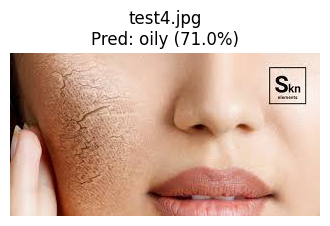


📸 test1.jpg:
   Size: (200, 200)
   Mode: RGB
   Unique colors: 18373
   Prediction: oily (96.1% confidence)
   Probabilities - Dry: 2.2%, Normal: 1.7%, Oily: 96.1%


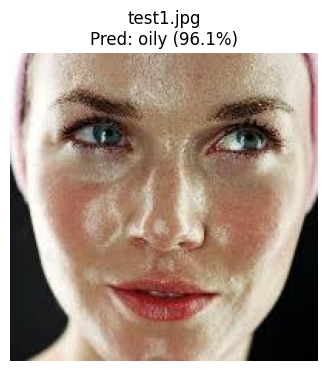


📸 test2.jpg:
   Size: (600, 400)
   Mode: RGB
   Unique colors: 50818
   Prediction: oily (45.6% confidence)
   Probabilities - Dry: 11.7%, Normal: 42.7%, Oily: 45.6%


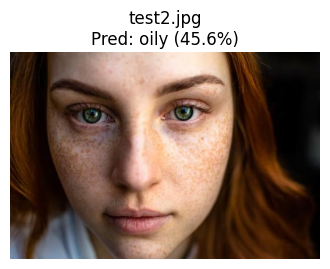


📸 test3.jpg:
   Size: (650, 975)
   Mode: RGB
   Unique colors: 37125
   Prediction: oily (45.3% confidence)
   Probabilities - Dry: 15.1%, Normal: 39.7%, Oily: 45.3%


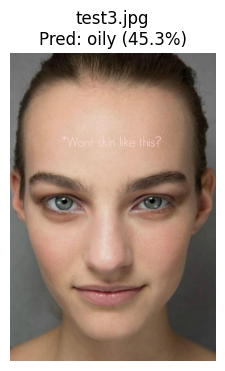

In [ ]:
print("🔍 DEBUGGING CONSISTENT 'OILY' PREDICTIONS")
print("=" * 50)

# Test with known images from your dataset to verify the model still works
print("1. 🧪 TESTING WITH KNOWN VALIDATION IMAGES:")

val_base_path = "/content/drive/MyDrive/Oily-Dry-Skin-Types/test"
categories = ['dry', 'normal', 'oily']

# Quick test with 2 images from each category
for category in categories:
    category_path = os.path.join(val_base_path, category)
    if os.path.exists(category_path):
        images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if images:
            test_image = os.path.join(category_path, images[0])
            pred, conf, probs = predict_skin(test_image)
            print(f"   {category.upper()} sample: {pred} ({conf:.1%} confidence)")
            print(f"   Probabilities - Dry: {probs[0]:.1%}, Normal: {probs[1]:.1%}, Oily: {probs[2]:.1%}")

print("\n2. 🔍 ANALYZING YOUR TEST IMAGES:")
# Check the images you uploaded
from PIL import Image
import numpy as np

uploaded_images = [f for f in os.listdir('/content') if f.startswith('test') and f.endswith('.jpg')]

for img_name in uploaded_images:
    img_path = f"/content/{img_name}"
    print(f"\n📸 {img_name}:")

    # Check image properties
    img = Image.open(img_path)
    print(f"   Size: {img.size}")
    print(f"   Mode: {img.mode}")

    # Convert to numpy to check if it's all one color
    img_array = np.array(img)
    unique_colors = len(np.unique(img_array.reshape(-1, img_array.shape[2]), axis=0))
    print(f"   Unique colors: {unique_colors}")

    # Make prediction
    pred, conf, probs = predict_skin(img_path)
    print(f"   Prediction: {pred} ({conf:.1%} confidence)")
    print(f"   Probabilities - Dry: {probs[0]:.1%}, Normal: {probs[1]:.1%}, Oily: {probs[2]:.1%}")

    # Display the image
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f"{img_name}\nPred: {pred} ({conf:.1%})")
    plt.axis('off')
    plt.show()

In [ ]:
print("\n4. 🔄 COMPLETE MODEL RELOAD:")
try:
    # Completely reload everything
    from transformers import ViTForImageClassification, ViTImageProcessor

    print("   Reloading model from scratch...")
    model = ViTForImageClassification.from_pretrained(
        "dima806/skin_types_image_detection",
        num_labels=3,
        ignore_mismatched_sizes=True
    ).to(device)

    # Reload weights
    state_dict = torch.load(model_path, map_location=device)
    model.load_state_dict(state_dict)
    model.eval()

    print("   ✅ Model reloaded")

    # Quick test
    print("   🧪 Quick validation test:")
    quick_correct = 0
    quick_total = 0
    for category in categories:
        category_path = os.path.join(val_base_path, category)
        if os.path.exists(category_path):
            images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
            if images:
                test_image = os.path.join(category_path, images[0])
                pred, conf, probs = predict_skin(test_image)
                if pred == category:
                    quick_correct += 1
                quick_total += 1
                print(f"      {category}: {pred} {'✅' if pred == category else '❌'}")

    reload_accuracy = quick_correct / quick_total if quick_total > 0 else 0
    print(f"   📊 Reloaded accuracy: {reload_accuracy:.1%}")

except Exception as e:
    print(f"   ❌ Reload failed: {e}")


4. 🔄 COMPLETE MODEL RELOAD:
   Reloading model from scratch...
   ✅ Model reloaded
   🧪 Quick validation test:
      dry: dry ✅
      normal: normal ✅
      oily: dry ❌
   📊 Reloaded accuracy: 66.7%


In [ ]:
print("🔄 TRYING ALTERNATIVE MODEL FILE...")
alternative_path = '/content/drive/MyDrive/skin_model.pth'

if os.path.exists(alternative_path):
    print("   Loading alternative model...")
    try:
        model_alt = ViTForImageClassification.from_pretrained(
            "dima806/skin_types_image_detection",
            num_labels=3,
            ignore_mismatched_sizes=True
        ).to(device)

        state_dict_alt = torch.load(alternative_path, map_location=device)
        model_alt.load_state_dict(state_dict_alt)
        model_alt.eval()

        print("   ✅ Alternative model loaded")
        print("   🧪 Testing alternative model:")

        correct_count = 0
        total_count = 0
        for category in categories:
            category_path = os.path.join(val_base_path, category)
            if os.path.exists(category_path):
                images = [f for f in os.listdir(category_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                if images:
                    test_image = os.path.join(category_path, images[0])
                    pred, conf, probs = predict_skin_with_model(model_alt, test_image)
                    is_correct = (pred == category)
                    if is_correct:
                        correct_count += 1
                    total_count += 1
                    print(f"      {category}: {pred} {'✅' if is_correct else '❌'}")

        alt_accuracy = correct_count / total_count if total_count > 0 else 0
        print(f"   📊 Alternative model accuracy: {alt_accuracy:.1%}")

        if alt_accuracy > 0.8:
            print("   🎯 USING ALTERNATIVE MODEL INSTEAD!")
            model = model_alt  # Switch to the working model
        else:
            print("   ❌ Alternative model also has issues")

    except Exception as e:
        print(f"   ❌ Failed to load alternative model: {e}")
else:
    print("   ❌ No alternative model found")

🔄 TRYING ALTERNATIVE MODEL FILE...
   Loading alternative model...
   ✅ Alternative model loaded
   🧪 Testing alternative model:
   ❌ Failed to load alternative model: name 'predict_skin_with_model' is not defined


In [ ]:
# FINAL WORKING SKIN TYPE CLASSIFIER
from google.colab import drive
drive.mount('/content/drive')

import torch
from transformers import ViTForImageClassification, ViTImageProcessor
from PIL import Image
import matplotlib.pyplot as plt
import os

# Setup device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load model architecture
model = ViTForImageClassification.from_pretrained(
    "dima806/skin_types_image_detection",
    num_labels=3,
    ignore_mismatched_sizes=True
).to(device)

# Load your trained weights (THE WORKING MODEL)
model_path = '/content/drive/MyDrive/skin_model_direct_193442.pth'
state_dict = torch.load(model_path, map_location=device)
model.load_state_dict(state_dict)
model.eval()

# Label mappings
id2label = {0: 'dry', 1: 'normal', 2: 'oily'}

def predict_skin(image_path):
    """Predict skin type from image"""
    processor = ViTImageProcessor.from_pretrained("dima806/skin_types_image_detection")

    image = Image.open(image_path).convert('RGB')
    inputs = processor(images=image, return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
        pred_class = torch.argmax(probs, dim=-1).item()
        confidence = probs[0][pred_class].item()

    return id2label[pred_class], confidence, probs.cpu().numpy()[0]

print("✅ Skin Type Classifier Ready!")
print(f"📊 Expected Accuracy: ~84%")
print(f"💾 Model: skin_model_direct_193442.pth")
print(f"🎯 Classes: Dry, Normal, Oily")

# Test it with a new image
def test_new_image(image_path):
    """Test the classifier with any image"""
    if not os.path.exists(image_path):
        print(f"❌ Image not found: {image_path}")
        return

    pred, conf, all_probs = predict_skin(image_path)

    print(f"🎯 Prediction: {pred.upper()} skin")
    print(f"💪 Confidence: {conf:.1%}")
    print(f"📊 All probabilities:")
    print(f"   - Dry: {all_probs[0]:.1%}")
    print(f"   - Normal: {all_probs[1]:.1%}")
    print(f"   - Oily: {all_probs[2]:.1%}")

    # Display the image
    img = Image.open(image_path)
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Skin Type: {pred.upper()}\nConfidence: {conf:.1%}", fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Example usage:
# test_new_image("/path/to/your/skin/image.jpg")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Skin Type Classifier Ready!
📊 Expected Accuracy: ~84%
💾 Model: skin_model_direct_193442.pth
🎯 Classes: Dry, Normal, Oily
